In [29]:
import sys
print(sys.executable)
print(sys.prefix)

/opt/anaconda3/envs/tumors/bin/python
/opt/anaconda3/envs/tumors


In [30]:
from pathlib import Path

# Support running from either eden_sim/ or the project directory.
SIM_DIR = Path.cwd() / "eden_sim" if Path("eden_sim").is_dir() else Path.cwd()
log_file = SIM_DIR / "data" / "log_eden_subsampled.tsv"

In [31]:
import pandas as pd
import dendropy

# Read IDs as strings to avoid converting missing-parent columns to floats.
df = pd.read_csv(
    log_file,
    sep = '\t',
    dtype={"id": "string", "parent_id": "string", "birth_date": "int", "death_date": "int", "states": "string"},
)

if df["id"].isna().any() or not df["id"].is_unique:
    raise ValueError("Each id must be unique and nonmissing.")

if "states" not in df.columns or not df["states"].isin(("edge", "center")).all():
    raise ValueError("Each individual must have a states value of 'edge' or 'center'.")

# The root is the individual whose parent_index is blank.
root_ids = df.loc[df["parent_id"].isna(), "id"].tolist()

if len(root_ids) != 1:
    raise ValueError("Expected exactly one root with a blank parent_index.")

# Create every node before connecting them: CSV row order does not matter.
nodes = {
    cell_id: dendropy.Node(label=cell_id)
    for cell_id in df["id"]
}

# Attach each individual to its parent.
for row in df.itertuples(index=False):
    if pd.isna(row.parent_id):
        continue

    if row.parent_id not in nodes:
        raise ValueError(f"Missing parent: {row.parent_id}")

    nodes[row.parent_id].add_child(nodes[row.id])

# Wrap the root node in a rooted Tree object.
tree = dendropy.Tree(
    seed_node=nodes[root_ids[0]],
    is_rooted=True,
)

if sum(1 for _ in tree.preorder_node_iter()) != len(nodes):
    raise ValueError("Some individuals do not connect to the root; check for cycles.")

print(tree.as_string(
    schema="newick",
    suppress_leaf_node_labels=False,
))

[&R] ((((((((((((((((((((((((1470)1359)1282,(((4156)3900)1492)1283)851)821)691)623)407)381)329)251)185)177)120)108)82)63)43)16)14,(((((((((((((((4126)2819)2094)1370)566)385)317)249)203)123)96)64)49)25,(((((((((((((((((((((3509)2702)2437)1950)1763)1550)1435)1259)1092)895,(((((3288)2199)1693)1549)1277)894)797)703)631)493)415)235)189)145)110)90)51)24)21,(((((((((((((((2885)1069)880)636)579,(((((((((2104)1752)1723)1504)1393)1225)952,((((((((3158)2481)2296)1939)1844)1725)1414,(((((4024)2536)2224)2034)1758)1415)1265)953)829)795)578)514)398,((((((((((((((3897)2778)2519)2416)2085)1697)1495)1378)1215)1147)857)813)614,(((((((3604)2230)1366)1165)940)866)819)615)537)399)387)275)205)169)102)73)37)28,(((((((((((((((((((2318)2142,((((3958)3078)2773)2596)2143)1935)1862)1615)1566)1310)1237)1128)1049)845)741)569)501)436)354)231)174)61)29)20)15)9)6,((((((((((((((((((((1920)1787)1320)1117)993)801)672)608)528)404)392)271)227)157)100,((((((((((((3122)1607)1452)1437)1267)827)671)495)357)276,((((((((((((((409

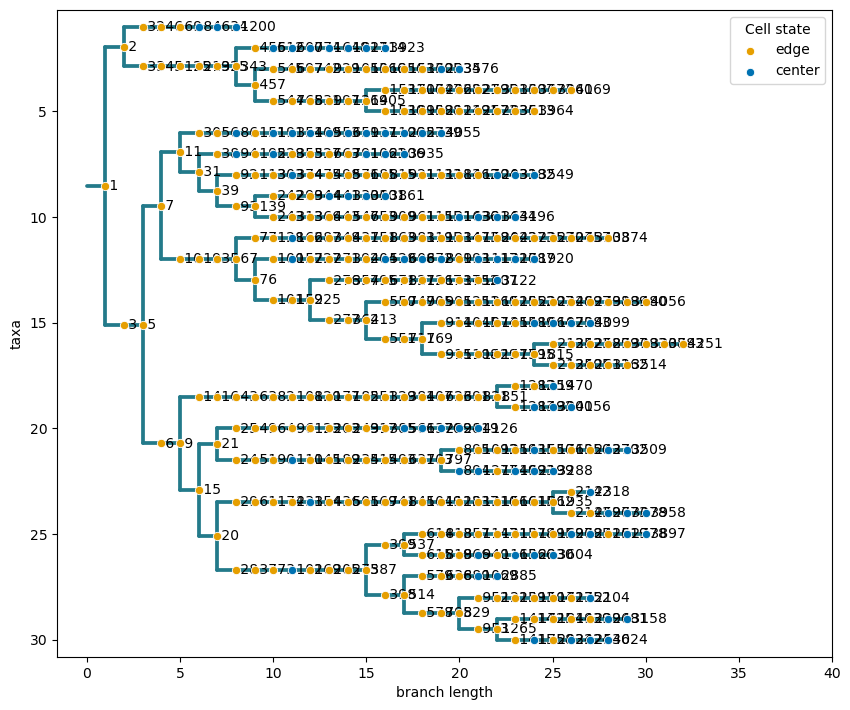

In [32]:
from Bio import Phylo
from Bio.Phylo.BaseTree import Tree, Clade
import matplotlib.pyplot as plt

# Convert DendroPy nodes into Biopython clades
# Direct conversion preseverse numeric IDs, including ancestor labels.
clades = {
    node: Clade(
        name=node.label or (node.taxon.label if node.taxon else None),
        branch_length=node.edge_length or 1
    )
    for node in tree.preorder_node_iter()
}

for node, clade in clades.items():
    clade.clades = [
        clades[child] for child in node.child_node_iter()
    ]

plot_tree = Tree(root=clades[tree.seed_node], rooted=True)
plot_tree.ladderize() # order branches by descendant count

# Stylying
plot_tree.root.color = "#237A8A"
plot_tree.root.width = 1.8

# Increase figure height with the number of leaves.
n_tips = plot_tree.count_terminals()
fig, ax = plt.subplots(figsize=(10, max(4, 0.28 * n_tips)))

Phylo.draw(
    plot_tree,
    axes=ax,
    do_show=False,
    show_confidence = False,
    label_func = lambda c: c.name,
)

# Node labels are anchored at each individual's position in the tree.
state_colors = {"edge": "#E69F00", "center": "#0072B2"}
state_by_id = df.set_index("id")["states"].to_dict()
node_positions = {
    label.get_text().strip(): label.get_position()
    for label in ax.texts
}

for state, color in state_colors.items():
    positions = [
        position for cell_id, position in node_positions.items()
        if state_by_id[cell_id] == state
    ]
    if not positions:
        continue
    ax.scatter(
        *zip(*positions),
        marker="o", s=36, color=color,
        edgecolors="white", linewidths=0.6,
        zorder=4, label=state,
    )

ax.legend(title="Cell state", loc="upper right")
plt.show()

In [33]:
n_tips

30